Import alla labraries

In [2]:
import pandas as pd
import  numpy as np
import matplotlib.pyplot  as plt 
import seaborn as sns

load walmart data

In [3]:
df=pd.read_csv("F:\\Project\\Walmart_project\\walmart_sales_analysis\\data\\Walmart_cleaned.csv",parse_dates=["Date"])

Check the datatypes of dataset

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Store         6435 non-null   int64         
 1   Date          6435 non-null   datetime64[ns]
 2   Weekly_Sales  6435 non-null   float64       
 3   Holiday_Flag  6435 non-null   int64         
 4   Temperature   6435 non-null   float64       
 5   Fuel_Price    6435 non-null   float64       
 6   CPI           6435 non-null   float64       
 7   Unemployment  6435 non-null   float64       
dtypes: datetime64[ns](1), float64(5), int64(2)
memory usage: 402.3 KB


In [5]:
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,2010-05-02,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,2010-12-02,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,2010-05-03,1554806.68,0,46.50,2.625,211.350143,8.106


# Visualization

Check outliers

In [6]:
for i in df.columns:
    if df[i].dtype != "object":
        q1 = df[i].quantile(0.25)
        q3= df[i].quantile(0.75)
        IQR = q3-q1
        lower=q1-1.5*IQR
        upper =q3+1.5*IQR

        outlier = df[(df[i]<lower)|(df[i]>upper)]
        print(i,":",len(outlier))

Store : 0
Date : 0
Weekly_Sales : 34
Holiday_Flag : 450
Temperature : 3
Fuel_Price : 0
CPI : 0
Unemployment : 481


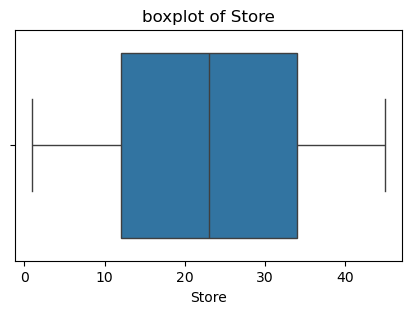

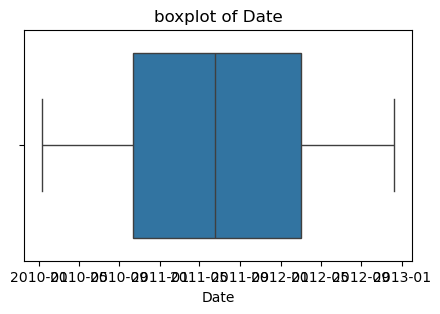

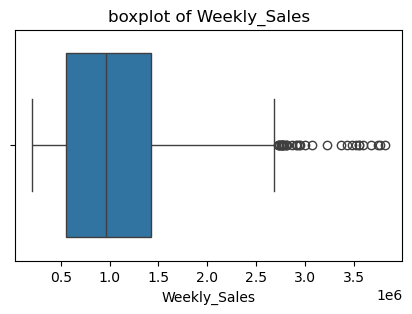

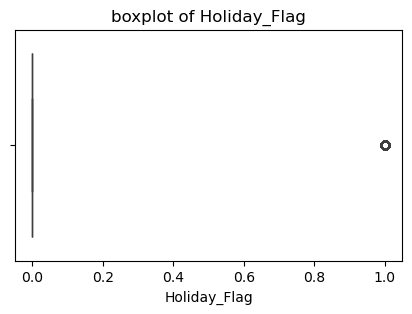

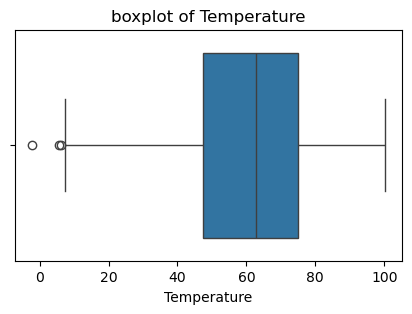

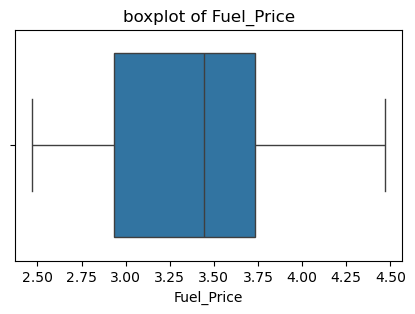

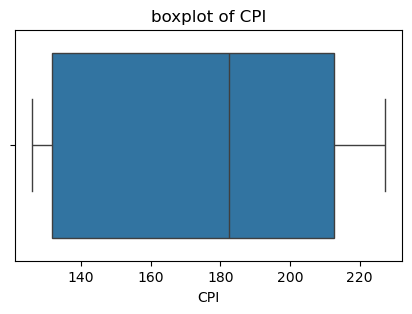

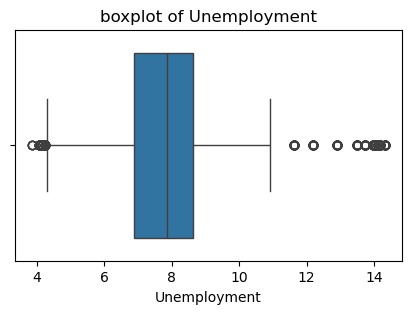

In [7]:
for i in df.columns:
    plt.figure(figsize=(5,3))
    sns.boxplot(x=df[i])
    plt.title(f'boxplot of {i}')
    plt.show()


Outlier are not removed because they may represent genuine variations in Walmart sales and economic conditions.


Top 10 stores by weekly sales

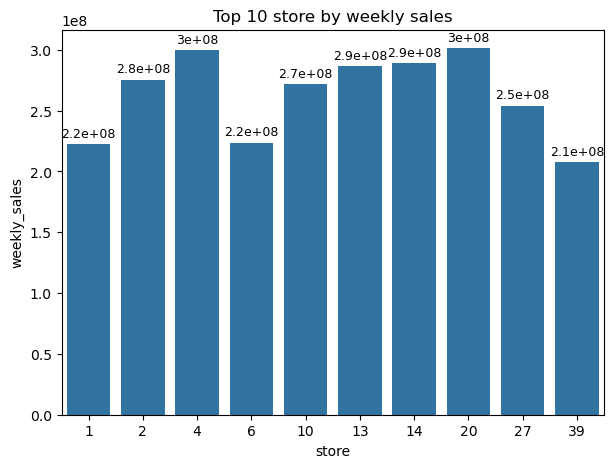

In [8]:
store_sales=df.groupby("Store")["Weekly_Sales"].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(7,5))
bar = sns.barplot(x=store_sales.index,y=store_sales.values)
plt.title("Top 10 store by weekly sales",color='black')
plt.xlabel("store")
plt.ylabel("weekly_sales")
for container in bar.containers:
    plt.bar_label(container,fmt="%.2g",padding=3,fontsize=9)
plt.show()


Store 4 and 20 has the highest weekly sales among the top 10 stores, while store 39 has the lowest.

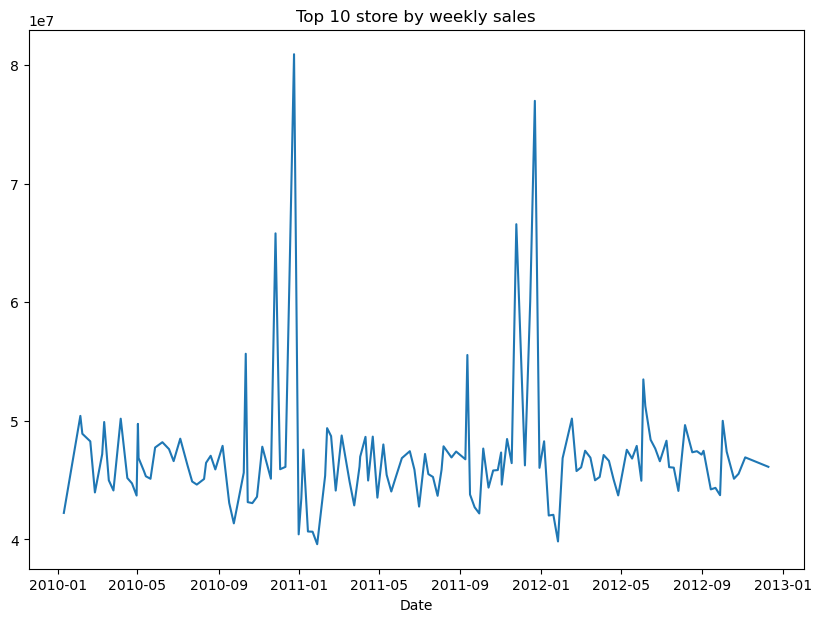

In [9]:
date= df.groupby('Date')['Weekly_Sales'].sum().sort_values(ascending=False)
plt.figure(figsize=(10,7))
sns.lineplot(x=date.index,y=date.values)
plt.title("Top 10 store by weekly sales",color='black')
plt.show()


C:\Users\DELL\AppData\Local\Temp\ipykernel_13676\3320374939.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bar=sns.barplot(x=holi.index,y=holi.values,palette='viridis')


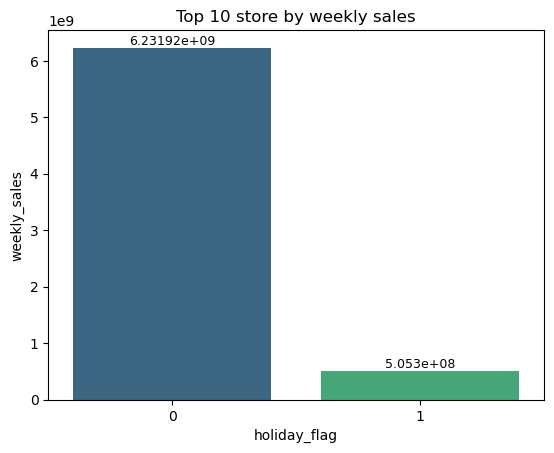

In [10]:
holi=df.groupby('Holiday_Flag')['Weekly_Sales'].sum()
bar=sns.barplot(x=holi.index,y=holi.values,palette='viridis')
plt.title("Top 10 store by weekly sales",color='black')
plt.xlabel("holiday_flag")
plt.ylabel("weekly_sales")
for container in bar.containers:
    plt.bar_label(container,fontsize=9)


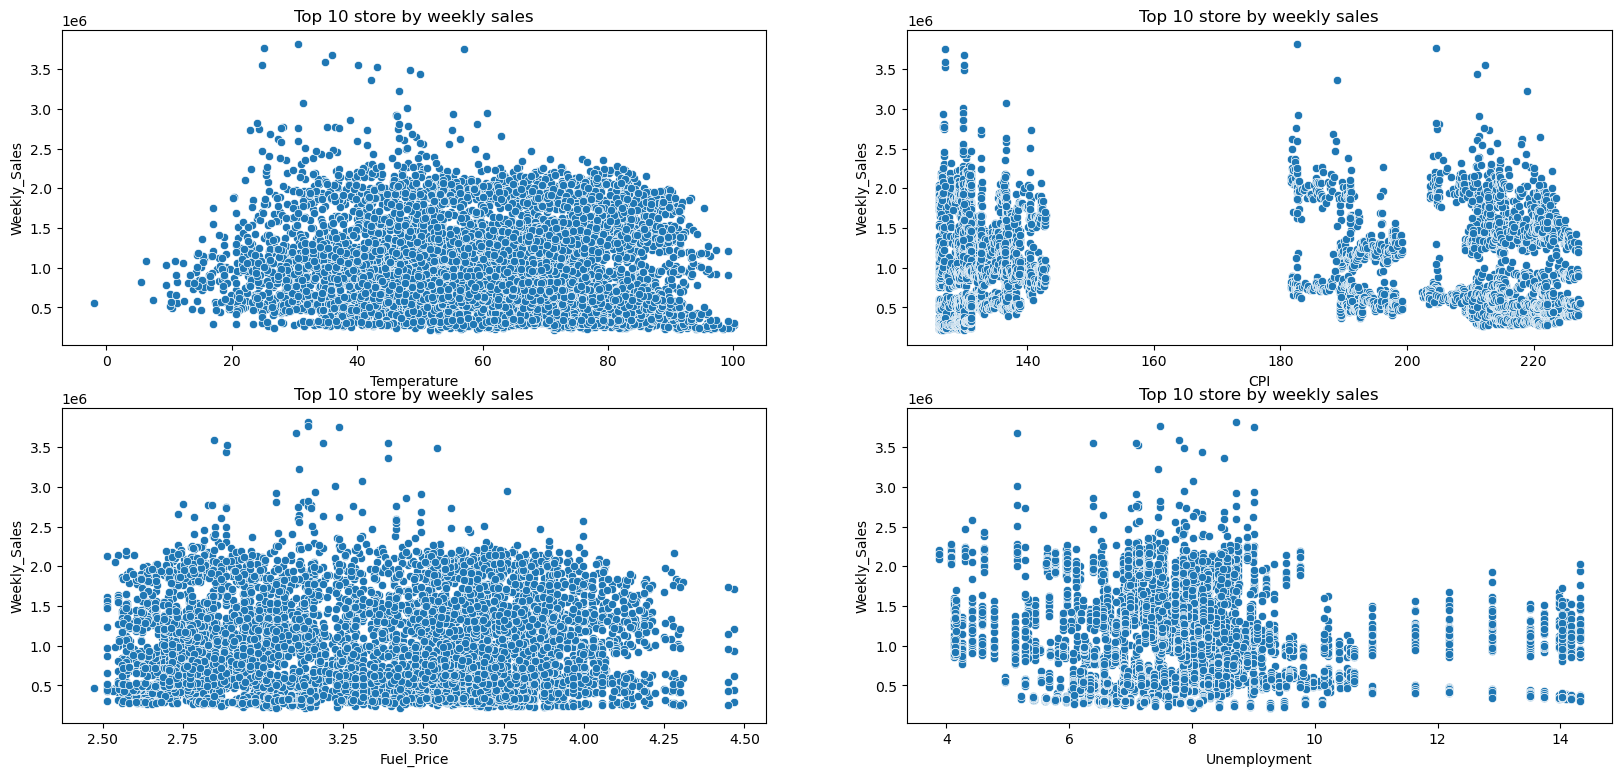

In [11]:


plt.subplots(2,2,figsize=(20,9))

plt.subplot(2,2,1)
sns.scatterplot(data=df,x='Temperature',y='Weekly_Sales')
plt.title("Top 10 store by weekly sales",color='black')

plt.subplot(2,2,2)
sns.scatterplot(data=df,x='CPI',y='Weekly_Sales')
plt.title("Top 10 store by weekly sales",color='black')


plt.subplot(2,2,3)
sns.scatterplot(data=df,x='Fuel_Price',y='Weekly_Sales')
plt.title("Top 10 store by weekly sales",color='black')

plt.subplot(2,2,4)
sns.scatterplot(data=df,x='Unemployment',y='Weekly_Sales')
plt.title("Top 10 store by weekly sales",color='black')
plt.show()
